# Indice de contenido
- [Importar librerias](#il)
- [Funciones auxiliares](#fa)
- [Clases auxiliares](#ca)
- [Seleccionar camara para calibracion](#sc)
    - [Camara Wifi](#cw)
    - [Camara USB](#cu)
    - [Camara Dual USB](#cdu)
- [Dimensiones de la imagen](#di) 
- [Cargar imagenes](#ci)
- [Seleccionar imagenes donde si se detecta el tablero de ajedrez](#si)
- [Filtrar imagenes para el proceso de calibracion](#fi)
- [Calibrar camara](#cc)
- [Guardar parametros de calibracion](#gp)
- [Cargar parametros de calibracion](#cp)
- [Informacion parametros de calibracion](#ip)
- [Eliminar la distorsion en las imagenes](#edi)
- [Comprobar parametros de calibracion con realidad aumentada](#cpc)

# Importar librerias <a class='anchor' id='il'>

In [1]:
import io
import os
import cv2
import time
import numpy as np
import pickle
import subprocess
import re
import shutil
import glob
import matplotlib
import matplotlib.pyplot as plt
import plotly
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import requests

pio.renderers.default = "notebook_connected"

# Configuramos la ruta para que use las fuentes recién instaladas
os.environ["QT_QPA_FONTDIR"] = "/usr/share/fonts/truetype/dejavu/"

%matplotlib inline

In [2]:
# Versiones de los paquetes utilizados
print('Versiones de los paquetes utilizados:')
print('\n'.join(f'{m.__name__}=={m.__version__}' for m in globals().values() if getattr(m, '__version__', None)))

Versiones de los paquetes utilizados:
cv2==5.0.0
numpy==2.4.3
re==2.2.1
matplotlib==3.11.1
plotly==6.5.0
requests==2.32.5


# Funciones auxiliares <a class='anchor' id='fa'>

In [3]:
# Muestra imagenes
def plot_image(image_bgr, title, figsize=(4,4)):
    image_rgb=cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    fig=plt.figure(figsize=figsize)
    plt.title(title)
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.show()

# Clases auxiliares <a class='anchor' id='ca'>

In [4]:
# Clase para dibujar puntos y lineas sobre una imagen
class DrawImage():
    def __init__(self):
        pass

    @staticmethod
    def draw_points(image_bgr, points, size=5, color_bgr=(0,255,0)):
        image_bgr_copy=np.copy(image_bgr)
        N=points.shape[0]
        for n in range(N):
            x,y=points[n].astype(int)
            image_bgr_copy=cv2.circle(image_bgr_copy, (x,y), size, color_bgr, -1)
        return image_bgr_copy

    @staticmethod
    def draw_lines(image_bgr, lines, color_bgr=(0,0,255), weight=2):
        image_bgr_copy=np.copy(image_bgr)
        points1,points2=lines
        N=points1.shape[0]
        for n in range(N):
            x1,y1=points1[n].astype(int)
            x2,y2=points2[n].astype(int)
            image_bgr_copy=cv2.line(image_bgr_copy, (x1,y1), (x2,y2), color_bgr, weight)
        return image_bgr_copy

In [5]:
# Clase para obtener puntos correspondientes 2D y 3D de un tablero de ajedrez y de un marcador ArUco.
# Sistema de coordenadas puntos 2D (OpenCV): X (derecha), Y (abajo)
# Sistema de coordenadas puntos 3D: X (abajo), Y (derecha), Z (arriba)
class Correspondences_2D_and_3D():
    # Diccionario para el marcador ArUco
    dict_aruco = dict({
    	"DICT_4X4_50" : cv2.aruco.DICT_4X4_50,
    	"DICT_4X4_100" : cv2.aruco.DICT_4X4_100,
    	"DICT_4X4_250" : cv2.aruco.DICT_4X4_250,
    	"DICT_4X4_1000" : cv2.aruco.DICT_4X4_1000,
    	"DICT_5X5_50" : cv2.aruco.DICT_5X5_50,
    	"DICT_5X5_100" : cv2.aruco.DICT_5X5_100,
    	"DICT_5X5_250" : cv2.aruco.DICT_5X5_250,
    	"DICT_5X5_1000" : cv2.aruco.DICT_5X5_1000,
    	"DICT_6X6_50" : cv2.aruco.DICT_6X6_50,
    	"DICT_6X6_100" : cv2.aruco.DICT_6X6_100,
    	"DICT_6X6_250" : cv2.aruco.DICT_6X6_250,
    	"DICT_6X6_1000" : cv2.aruco.DICT_6X6_1000,
    	"DICT_7X7_50" : cv2.aruco.DICT_7X7_50,
    	"DICT_7X7_100" : cv2.aruco.DICT_7X7_100,
    	"DICT_7X7_250" : cv2.aruco.DICT_7X7_250,
    	"DICT_7X7_1000" : cv2.aruco.DICT_7X7_1000,
    })

    def __init__(self):
        pass

    @staticmethod
    def points_2D_from_aruco_marker(image_bgr, aruco_type, aruco_id):
        if image_bgr is not None:
            dictionary=cv2.aruco.getPredefinedDictionary(Correspondences_2D_and_3D.dict_aruco[aruco_type])
            parameters=cv2.aruco.DetectorParameters()
            detector=cv2.aruco.ArucoDetector(dictionary, parameters)
            # Las detecciones se hacen en sentido de las manecillas del reloj
            corners,ids,rejected=detector.detectMarkers(image_bgr)
            if len(corners) > 0:
                res=np.where(ids == aruco_id)[0]
                if len(res) > 0:
                    pos=res[0]
                    points=corners[pos].squeeze()
                    return points  
        return None

    @staticmethod
    def points_3D_from_aruco_marker(square_size):
        T=np.eye(2) * square_size
        points=T @ np.array([[0,0,1,1],[0,1,1,0]])
        points=np.vstack([points, np.zeros((1, points.shape[1]))]).T
        return points
    
    @staticmethod
    def points_2D_from_chessboard(image_bgr, chessboard_dimensions, fast=True):
        if image_bgr is not None:
            image_gray=cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
            # Las detecciones se hacen de izquierda a derecha, de arriba a abajo
            # Corners shape: (N, 1, 2)
            ret,corners=cv2.findChessboardCorners(image_gray, chessboard_dimensions, None, flags=cv2.CALIB_CB_FAST_CHECK) if fast else cv2.findChessboardCorners(image_gray, chessboard_dimensions, None)
            if ret:
                points=corners.squeeze()
                return points
        return None

    @staticmethod
    def points_3D_from_chessboard(chessboard_dimensions, square_size):
        N=int(np.prod(chessboard_dimensions))
        w,h=chessboard_dimensions
        points=np.zeros((N,3))
        count=0
        T=np.eye(2) * square_size
        for x in range(h):
            for y in range(w):
                v=np.array([[x],[y]])
                u=(T @ v).flatten()
                points[count]=np.array([u[0],u[1],0])
                count+=1
        return points

    @staticmethod
    def correspondences_2D_and_3D_from_aruco_marker(image_bgr, aruco_type, aruco_id, square_size):
        points_2D=Correspondences_2D_and_3D.points_2D_from_aruco_marker(image_bgr=image_bgr, aruco_type=aruco_type, aruco_id=aruco_id)
        points_3D=Correspondences_2D_and_3D.points_3D_from_aruco_marker(square_size=square_size)
        return (points_2D,points_3D,True) if points_2D is not None and points_3D is not None else (None,None,False)

    @staticmethod
    def correspondences_2D_and_3D_from_chessboard(image_bgr, chessboard_dimensions, square_size, fast=True):
        points_2D=Correspondences_2D_and_3D.points_2D_from_chessboard(image_bgr=image_bgr, chessboard_dimensions=chessboard_dimensions, fast=fast)
        points_3D=Correspondences_2D_and_3D.points_3D_from_chessboard(chessboard_dimensions=chessboard_dimensions, square_size=square_size)
        return (points_2D,points_3D,True) if points_2D is not None and points_3D is not None else (None,None,False)

In [6]:
class PlotExtrinsicMatrix():
    def __init__(self):
        pass

    # Grafico 3D con Plotly
    @staticmethod
    def plotly_figure(title=''):
        fig = go.Figure(data=[])
        fig.update_layout(
            scene=dict(
                xaxis_title='x',
                yaxis_title='y',
                zaxis_title='z',
                # xaxis = dict(nticks=None, range=[-1,1]),
                # yaxis = dict(nticks=None, range=[-1,1]),
                # zaxis = dict(nticks=None, range=[-1,1]),
                # aspectmode='cube',
                # aspectratio=dict(x=1, y=1, z=1),
                camera=dict(
                    eye=dict(x=1.5, y=-1.5, z=1.5) 
                )
            ),
            title=dict(
                text=title,
                font=dict(
                    family="Arial",
                    size=24,
                    color="red"
                ),
                x=0.5, 
                xanchor="center"
            ), 
            autosize=False,
            width=800, 
            height=500,
            margin=dict(l=40, r=40, b=40, t=40),
            showlegend=False,
            legend=dict(
                yanchor="top",
                y=0.99,
                xanchor="left",
                x=0.01,
                font=dict(
                    family="Courier",
                    size=14,
                    color="black"
                ),
                itemsizing="constant"
            )
        )
        return fig
    
    # Dibujar sistema de coordenadas 
    @staticmethod
    def plot_coordinate_system(fig, Tsm, tsm, text='', subprefix=''):
        axis_color=['red','green','blue']
        axis_name=['X','Y','Z']
        cs=np.array([[0,0,0,1],[1,0,0,1],[0,1,0,1],[0,0,1,1]]).T
        Hsm=np.concatenate([np.concatenate([Tsm, tsm], axis=1), np.array([[0,0,0,1]])], axis=0)
        ps=(Hsm @ cs)[0:3,:]
        # Puntos
        fig.add_scatter3d(
            x=ps[0,:], 
            y=ps[1,:], 
            z=ps[2,:], 
            mode='markers', 
            marker=dict(size=6, symbol="circle", color='black'),
        )
        # Nombre de los ejes
        for j in range(3):
            fig.add_scatter3d(
                x=[ps[0,1 + j]], 
                y=[ps[1,1 + j]], 
                z=[ps[2,1 + j]], 
                mode='text', 
                text=f'{axis_name[j]}<sub>{subprefix}</sub>'
            )
        # Texto
        fig.add_scatter3d(
            x=[ps[0,0]], 
            y=[ps[1,0]], 
            z=[ps[2,0]], 
            mode='text', 
            text=text,
        )
        # Lineas
        for j in range(3):
            fig.add_scatter3d(
                x=[ps[0,0],ps[0,j+1]], 
                y=[ps[1,0],ps[1,j+1]], 
                z=[ps[2,0],ps[2,j+1]], 
                mode='lines', 
                line=dict(width=5, color=axis_color[j])
            )
        return fig
    
    # Para mostrar las matrices extrinsecas
    @staticmethod
    def plot_extrinsic_matrices(Qs):
        # Mostramos solo una a la vez de forma aleatoria
        index=np.random.randint(0, Qs.shape[0])
        Q=Qs[index]
        # Grafico 3D
        fig=PlotExtrinsicMatrix.plotly_figure(title='Matriz extrinseca (unidades en metros)<br>Los ejes no estan a escala')
        # Definimos como esta rotado y posicionado el sistema de coordenadas de la camara con respecto al sistema de coordenadas de plotly
        Tcm=np.array([[0,0,1],[-1,0,0],[0,-1,0]])
        tcm=np.zeros((3,1))
        Hcm=np.vstack([np.hstack([Tcm, tcm]), np.ones((1,4))])
        fig=PlotExtrinsicMatrix.plot_coordinate_system(fig, Tsm=Tcm, tsm=tcm, text='S.C. Camara', subprefix='c')
        # Definimos como esta rotado y posicionado el sistema de coordenadas del mundo con respecto al sistema de coordenadas de plotly
        Hwc=np.vstack([Q, np.ones((1,4))])
        Hwm=Hcm @ Hwc
        Twm=Hwm[:3,:3]
        twm=Hwm[:3,[3]] / 1000 # mm a mts
        fig=PlotExtrinsicMatrix.plot_coordinate_system(fig, Tsm=Twm, tsm=twm, text=f'S.C. Mundo {index + 1}', subprefix='w')
        return fig

In [7]:
class PinholeCameraModel():
    def __init__(self):
        pass

    # Dado el modelo ideal, devuelve el punto 2D sin distorsion
    @staticmethod
    def projection_ideal_camera_model(vws, K, Q):
        us_=K @ Q @ np.concatenate([vws, np.ones((vws.shape[0],1))], axis=1).T
        us_=us_ / us_[-1,:]
        us=us_[[0,1],:].T
        return us
    
    # Dado el modelo no ideal, devuelve el punto 2D distorsionado
    @staticmethod
    def projection_non_ideal_camera_model(vws, K, Q, q):
        N=vws.shape[0]
        uds=np.zeros((N,2))
        k1,k2,p1,p2,k3=q.flatten()
        for i in range(N):
            vw_=np.concatenate([vws[[i],:].T, np.ones((1,1))], axis=0)
            vc=Q @ vw_
            xc,yc,zc=vc.flatten()
            vn=np.array([
                [xc / zc],
                [yc / zc]
            ])
            r=np.linalg.norm(vn)
            xn,yn=vn.flatten()
            d=np.array([
                [xn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + 2 * p1 * xn * yn + p2 * (r**2 + 2 * xn**2)],
                [yn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + p1 * (r**2 + 2 * yn**2) + 2 * p2 * xn * yn]
            ])
            vnd=vn + d
            vnd_=np.concatenate([vnd, np.ones((1,1))], axis=0)
            ud_=K @ vnd_
            ud=ud_[[0,1],:]
            uds[i]=ud.flatten()
        return uds
    
    # Calcula la matriz extrinseca de la camara 
    @staticmethod
    def calculate_Q(us_2D, vws_2D, K):
        # Homografia entre el plano de imagen y el plano del tablero
        H=PinholeCameraModel.calculate_homography(us_2D, vws_2D)
        h1,h2,h3=H[:,[0]],H[:,[1]],H[:,[2]]
        K_inv=np.linalg.inv(K)
        alpha=1/(np.linalg.norm(K_inv @ h1))
        twc=alpha * K_inv @ h3
        if twc[-1,0] < 0:
            alpha*=-1
            twc*=-1
        iwc=alpha * K_inv @ h1
        jwc=alpha * K_inv @ h2
        kwc=np.cross(iwc.flatten(),jwc.flatten())[:,None]
        Q=np.hstack([iwc,jwc,kwc,twc])
        return Q

    # Elimina la distorsion de los puntos distorsionados
    @staticmethod
    def undistorted_points(uds, K, q):
        # Obtenemos los puntos normalizados sin distorsion
        vns=cv2.undistortPoints(uds[:,None,:].astype('float32'), K, q)
        vns=vns.squeeze()
        vns_=np.concatenate([vns, np.ones((vns.shape[0],1))], axis=1)
        # Obtenemos los puntos sin distorsion sobre el plano de imagen 
        us_=(K @ vns_.T).T
        us=us_[:,[0,1]]
        return us

    # Elimina la distorsion de una imagen
    @staticmethod
    def undistorted_image_bgr(distorted_image_bgr, K, q):
        # Eliminamos la distorsion en la imagen
        return cv2.undistort(distorted_image_bgr, K, q, None, K)

    # Calcula una homografia
    # points1: (N,2)
    # points2: (N,2)
    @staticmethod
    def calculate_homography(points1, points2):
        # Descomposicion SVD de una matriz
        # u,s,vh=np.linalg.svd(A)
        # The rows of vh are the eigenvectors of A'A and the columns of u are the eigenvectors of AA'. 
        # In both cases the corresponding (possibly non-zero) eigenvalues are given by s**2.
        N=points1.shape[0]
        A=np.zeros((2 * N, 9))
        for i in range(N):
            x,y=points1[i]
            v_=np.hstack([points2[[i],:], np.ones((1,1))]).T
            A[2 * i:2 * (i + 1)]=np.vstack([
                np.hstack([v_.T, np.zeros((1,3)), -x * v_.T]), 
                np.hstack([np.zeros((1,3)), v_.T, -y * v_.T])
            ])
        u,s,vh=np.linalg.svd(A)
        H=np.reshape(vh[-1], (3,3), order='C')
        return H

In [8]:
"""
calibration_parameters
    - 'S'
    - 'chessboard'
        - 'dimensions'
        - 'size'
    - 'camera'
        - 'error'
        - 'K'
        - 'q'
        - 'Qs'
"""
class CameraTemplate():
    def __init__(self, name, opencv_id):
        self.name=name
        self.opencv_id=opencv_id
        self.calibration_parameters=None
        self.path_calibration_parameters=os.path.join(os.getcwd(), *['calibration parameters', self.name])

    # Sobreescribir este metodo si se requiere preprocesar la imagen
    def image_preprocessing(self, image_bgr):
        return image_bgr
        
    def save_calibration_parameters(self):
        if self.calibration_parameters is not None:
            # Creamos la carpeta si no existe
            if not os.path.exists(self.path_calibration_parameters):
                os.makedirs(self.path_calibration_parameters)
            with open(os.path.join(self.path_calibration_parameters, *['calibration_parameters.dat']), "wb") as f:
                pickle.dump(self.calibration_parameters, f)
                return True
        return False

    def load_calibration_parameters(self):
        # Ruta al archivo
        path=os.path.join(self.path_calibration_parameters, *['calibration_parameters.dat'])
        try:
            with open(path, "rb") as f:
                self.calibration_parameters=pickle.load(f)
                return True
        except (OSError, IOError) as e:
            self.calibration_parameters=None
            # raise Exception("La camara no esta calibrada :(")
        return False
    
    def print_calibration_parameters(self):
        if self.calibration_parameters is not None:
            S=self.calibration_parameters['S']
            chessboard_dimensions=self.calibration_parameters['chessboard']['dimensions']
            square_size=self.calibration_parameters['chessboard']['size']
            error=self.calibration_parameters['camera']['error']
            K=self.calibration_parameters['camera']['K']
            q=self.calibration_parameters['camera']['q']
            Qs=self.calibration_parameters['camera']['Qs']

            print(f'\nNumero de imagenes del tablero de ajedrez: {S}')
            print(f'\nDimensiones el tablero de ajedrez: {chessboard_dimensions}')
            print(f'\nTamaño de los cuadrados del tablero de ajedrez (en mm): {square_size}')
            print(f'\nError de reproyección RMS general: {error}')
            print(f'\nMatriz intrinseca: \n{K}')
            print(f'\nParametros de distorsion: \n{q}')
            print(f'\nMatrices extrinsecas: \n{Qs}')
    
    # Muestra la camara y toma una imagen 
    def show_camera(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr=None
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret,image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr=self.image_preprocessing(image_bgr)
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, image_bgr)
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except cv2.error as e:
                print("cv2.error: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr

    # Realidad aumentada
    def camera_augmented_reality(self, fast=False, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        if self.calibration_parameters is not None:
            failure_counter=0
            chessboard_dimensions=self.calibration_parameters['chessboard']['dimensions']
            square_size=self.calibration_parameters['chessboard']['size']
            K=self.calibration_parameters['camera']['K']
            q=self.calibration_parameters['camera']['q']
            # Abrimos la camara
            cap=cv2.VideoCapture(self.opencv_id, apiPreference)
            # Cambiar resolucion
            if frame_width is not None and frame_height is not None:
                cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
                cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
            # Asignamos un nombre a la ventana
            cv2.namedWindow(self.name)
            while failure_counter < max_number_of_failures:
                try:
                    if cap is not None:
                        if cap.isOpened():
                            # Reiniciamos contador de fracasos
                            failure_counter=0
                            # Captura de la imagen actual de la camara
                            ret, distorted_image_bgr=cap.read()
                            # Dimensiones: (height,width,deep)
                            if ret:
                                distorted_image_bgr=self.image_preprocessing(distorted_image_bgr)
                                # Eliminamos la distorsion en la imagen
                                undistorted_image_bgr=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr, K, q)
                                
                                # Dibujamos un rectangulo sobre el tablero
                                # Obtener pares de puntos correspondientes 2D y 3D del tablero de ajedrez (los puntos 3D estan en milimetros y tienen componente z=0)
                                us,vws,is_ok=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_chessboard( 
                                    image_bgr=undistorted_image_bgr, 
                                    chessboard_dimensions=chessboard_dimensions, 
                                    square_size=square_size, 
                                    fast=fast
                                )
                                if is_ok:
                                    # Dimensiones del tablero de ajedrez
                                    wb,hb=chessboard_dimensions
                                    # Indices de los puntos de las 4 esquinas
                                    indexes_corners=[0,wb - 1,wb * (hb - 1),wb * hb - 1]
                                    # Puntos 2D y 3D de las 4 esquinas
                                    us=us[indexes_corners]
                                    vws=vws[indexes_corners]
                                    # Matriz extrinseca de la camara
                                    Q=PinholeCameraModel.calculate_Q(us, vws[:,[0,1]], K)
                                    # Puntos 3D de las 4 esquinas inferiores y superiores
                                    rectangle_height=80 # en mm
                                    vws_bottom=np.copy(vws)
                                    vws_top=np.copy(vws)
                                    vws_top[:,2]=rectangle_height
                                    vws=np.concatenate([vws_bottom, vws_top], axis=0)
                                    # Conexiones entre los puntos (12 bordes del rectangulo)
                                    connections=[(0,1),(1,3),(3,2),(2,0),(4,5),(5,7),(7,6),(6,4),(0,4),(1,5),(3,7),(2,6)]
                                    # Proyeccion de los puntos 3D
                                    points=PinholeCameraModel.projection_ideal_camera_model(vws, K, Q)
                                    # Se relacionan las conexiones con los puntos 2D
                                    points1=np.zeros((len(connections),2))
                                    points2=np.zeros((len(connections),2))
                                    for i in range(len(connections)):
                                        p1,p2=connections[i]
                                        points1[i]=points[p1]
                                        points2[i]=points[p2]
                                    # Se dibujan los puntos 2D de todas las esquinas del rectangulo sobre la imagen
                                    undistorted_image_bgr=DrawImage.draw_points(image_bgr=undistorted_image_bgr, points=points, size=5, color_bgr=(0,255,0))
                                    # Se dibujan las lineas 2D de todos los bordes del rectangulo sobre la imagen
                                    undistorted_image_bgr=DrawImage.draw_lines(image_bgr=undistorted_image_bgr, lines=(points1,points2), color_bgr=(0,0,255), weight=2)
                                
                                # Se muestra lo que captura la camara
                                cv2.imshow(self.name, undistorted_image_bgr)
                                key=cv2.waitKey(1)
                                
                                # Condicion de parada
                                if key == ord('q'):
                                    break 
                            else:
                                failure_counter+=1
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                except cv2.error as e:
                    print("(cv2.error): {}".format(e))
                    break
            cap.release()
            cv2.destroyAllWindows()

In [9]:
class WifiCamera(CameraTemplate):
    def __init__(self, name, opencv_id):
        super().__init__(name, opencv_id)

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        image_bgr=cv2.rotate(image_bgr, cv2.ROTATE_90_CLOCKWISE)
        return image_bgr
        
    # Cambiar la resolucion de la imagen
    @staticmethod
    def esp32_cam_change_resolution(esp32_IP, val=7):
        # Valores de configuración
        var = "framesize"
        # Construimos la URL
        URL = f"http://{esp32_IP}/control?var={var}&val={str(val)}"
        try:
            print(f"Enviando petición a: {URL}")
            # Realizamos la petición GET directa
            response = requests.get(URL, timeout=5)
            # Verifica si la petición fue exitosa
            if response.status_code == 200:
                print("¡Resolución cambiada con éxito!")
                print("Respuesta del servidor:", response.text)
            else:
                print(f"Error en el servidor. Código de estado: {response.status_code}")
        except requests.exceptions.RequestException as e:
            print(f"No se pudo conectar con el ESP32-CAM: {e}")

In [10]:
class USBCamera(CameraTemplate):
    def __init__(self, name, opencv_id):
        super().__init__(name, opencv_id)

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        return image_bgr
        
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

In [11]:
class USBDualCamera(CameraTemplate):
    """
    Tengo entendido que se devuelve una sola imagen que concatena la imagen de cada camara.
    Podriamos especificar cual camara queremos (izquierda o derecha, 1 o 2) para recortar la imagen original.
    """
    def __init__(self, name, opencv_id, side):
        super().__init__(f"{name}-{side}", opencv_id)
        """
        Viendo las camaras de la parte de atras:
            - La camara 'left' se encuentra al lado izquierdo
            - La camara 'right' se encuentra al lado derecho
        """
        self.side=side # left, right

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        h,w,d=image_bgr.shape
        wc=w // 2
        img_bgr=None
        if self.side == "left":
            img_bgr = image_bgr[:, :wc, :]
        if self.side == "right":
            img_bgr = image_bgr[:, wc:, :]
        return img_bgr
        
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBDualCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

# Seleccionar camara para calibracion <a class='anchor' id='sc'>

OpenCV inicializa cualquier cámara web a una resolución estándar de 640x480 píxeles. OpenCV hace esto de manera automática independientemente de si tienes una cámara Full HD o 4K.

## Camara Wifi <a class='anchor' id='cw'>

In [26]:
# Cambiar la resolucion de la imagen de la ESP32 CAM
esp32_IP="192.168.100.91" 
WifiCamera.esp32_cam_change_resolution(esp32_IP=esp32_IP, val=8)

Enviando petición a: http://192.168.100.91/control?var=framesize&val=8
¡Resolución cambiada con éxito!
Respuesta del servidor: 


In [27]:
name=f"esp32_cam_{esp32_IP.split(".")[-1]}"
opencv_id=f"http://{esp32_IP}:81/stream"
print(f"URL del stream: {opencv_id}")

URL del stream: http://192.168.100.91:81/stream


In [28]:
frame_width=640
frame_height=480
apiPreference=cv2.CAP_ANY
# Camara Wifi
camera=WifiCamera(name, opencv_id)
# Mostrar lo que captura la camara
image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference)

## Camara USB <a class='anchor' id='cu'>

In [11]:
name,opencv_id=USBCamera.select_camera()
print()
print(f"Nombre: {name}")
print(f"ID opencv: {opencv_id}")


****************************************************************************************************

Camaras disponibles: 
	 1)  ('HX-USB Camera: HX-USB Camera', '/dev/video4')
	 2)  ('4k Camera: 4k Camera', '/dev/video0')
	 3)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  2



Nombre: 4k Camera: 4k Camera
ID opencv: /dev/video0


In [12]:
frame_width=640
frame_height=480
apiPreference=cv2.CAP_V4L
# Camara USB
camera=USBCamera(name, opencv_id)
# Mostrar lo que captura la camara
image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference)

## Camara Dual USB <a class='anchor' id='cdu'>

In [12]:
name,opencv_id=USBDualCamera.select_camera()
print()
print(f"Nombre: {name}")
print(f"ID opencv: {opencv_id}")


****************************************************************************************************

Camaras disponibles: 
	 1)  ('USB Camera: USB Camera', '/dev/video0')
	 2)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  1



Nombre: USB Camera: USB Camera
ID opencv: /dev/video0


In [26]:
frame_width=1280
frame_height=480
apiPreference=cv2.CAP_V4L
# Camara USB
camera=USBDualCamera(name, opencv_id, side="right")
# Mostrar lo que captura la camara
image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

# Dimensiones de la imagen <a class='anchor' id='di'>

In [27]:
print(f"Dimensiones de la imagen: {image_bgr.shape}")

Dimensiones de la imagen: (480, 640, 3)


# Cargar imagenes <a class='anchor' id='ci'>

Las imagenes deben estar en formato JPG en el siguiente directorio:
**./calibration images/\<camera name>**

Informacion del tablero de ajedrez: {'chessboard_dimensions': (9, 6), 'square_size': 25.0}


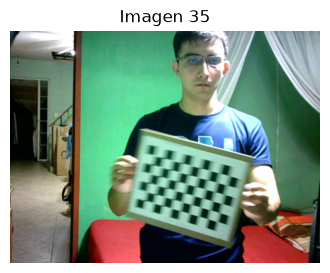

In [28]:
# Ruta donde se guardaron las imagenes
folder_name=os.path.join(os.getcwd(), *['calibration images', camera.name])

# Cargamos los datos del tablero de ajedrez
d=None
with open(os.path.join(folder_name, *['chessboard_information.pkl']), "rb") as file:
    d=pickle.load(file)

# Leemos las imagenes
image_bgr_list=[]
file_names=sorted(glob.glob(os.path.join(folder_name, *["*.jpg"])))
for file_name in file_names:
    image_brg=cv2.imread(file_name)
    image_bgr_list.append(image_brg)

print(f"Informacion del tablero de ajedrez: {d}")

# Imagen aleatoria
index=np.random.randint(len(image_bgr_list))
image_bgr=image_bgr_list[index]
plot_image(image_bgr, title=f"Imagen {index + 1}", figsize=(4,4))

# Seleccionar imagenes donde si se detecta el tablero de ajedrez <a class='anchor' id='si'>

In [29]:
# Datos del tablero de ajedrez 
chessboard_dimensions=d["chessboard_dimensions"]
square_size=d["square_size"]

# Guardamos solo las imagenes en donde se detecto el table de ajedrez
good_images=[]
for i in range(len(image_bgr_list)):
    image_bgr=image_bgr_list[i]
    # Dado que damos una imagen distorsionada, los puntos 2D tambien estar distorsionados
    uds,vws,is_ok=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_chessboard(
        image_bgr=image_bgr, 
        chessboard_dimensions=chessboard_dimensions, 
        square_size=square_size, 
        fast=False
    )
    if is_ok:
        good_images.append((image_bgr, uds, vws))

print("Imagenes buenas: {} (de un total de {})".format(len(good_images), len(image_bgr_list)))

Imagenes buenas: 58 (de un total de 60)


# Filtrar imagenes para el proceso de calibracion <a class='anchor' id='fi'>

Es muy importante filtrar las malas detecciones de las esquinas internas del tablero de ajedrez, lo cual es un proceso manual.

Las detecciones deben ser lo mas precisas posibles para obtener buenos resultados en el proceso de calibracion.

Recordar que las detecciones no son perfectas.

<center>
<h1>Ejemplo de buenas detecciones</h1>
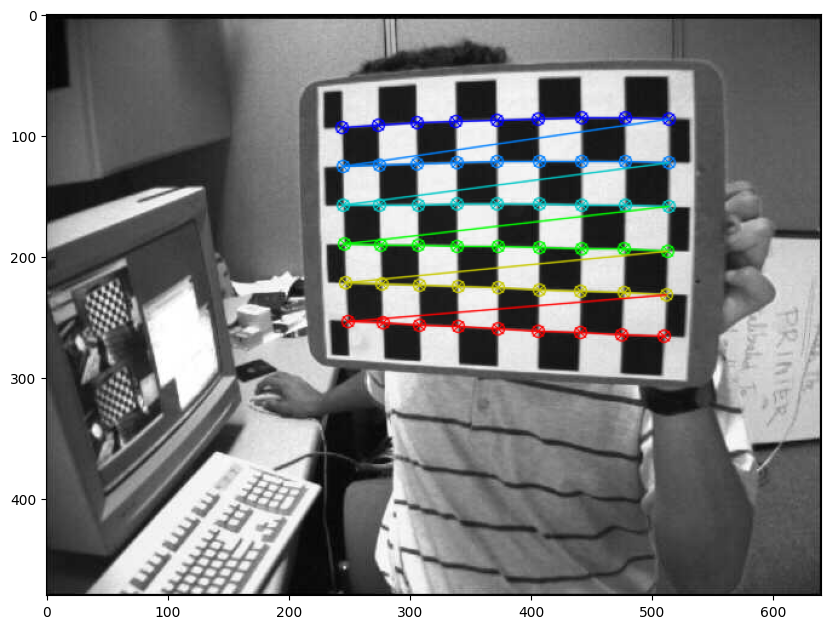
</center>

In [30]:
filtered_good_images=[]
for i in range(len(good_images)):
    image_bgr,uds,vws=good_images[i]
    # Copia de la imagen
    image_bgr_copy=image_bgr.copy()
    # Mostrar puntos detectados en las imagenes
    image_bgr_copy=DrawImage.draw_points(image_bgr=image_bgr_copy, points=uds, size=5, color_bgr=(0,0,255))
    # Resultados OpenCV
    image_bgr_copy=cv2.drawChessboardCorners(image_bgr_copy, chessboard_dimensions, uds, True)
    
    cv2.imshow(f"Imagen {i + 1} (Presionar '+' para guardar | Presionar '-' para eliminar)", image_bgr_copy)
    key=cv2.waitKey(0)
    if key == ord('+'):
        filtered_good_images.append(good_images[i] + (image_bgr_copy,))
        print(f'Imagen {i + 1} guardada')
    else:
        print(f'Imagen {i + 1} eliminada')
    cv2.destroyAllWindows()

Imagen 1 guardada
Imagen 2 guardada
Imagen 3 guardada
Imagen 4 guardada
Imagen 5 eliminada
Imagen 6 guardada
Imagen 7 eliminada
Imagen 8 guardada
Imagen 9 eliminada
Imagen 10 eliminada
Imagen 11 guardada
Imagen 12 eliminada
Imagen 13 guardada
Imagen 14 eliminada
Imagen 15 guardada
Imagen 16 guardada
Imagen 17 guardada
Imagen 18 eliminada
Imagen 19 guardada
Imagen 20 guardada
Imagen 21 guardada
Imagen 22 guardada
Imagen 23 guardada
Imagen 24 eliminada
Imagen 25 eliminada
Imagen 26 eliminada
Imagen 27 guardada
Imagen 28 guardada
Imagen 29 eliminada
Imagen 30 eliminada
Imagen 31 eliminada
Imagen 32 guardada
Imagen 33 guardada
Imagen 34 eliminada
Imagen 35 guardada
Imagen 36 eliminada
Imagen 37 eliminada
Imagen 38 eliminada
Imagen 39 guardada
Imagen 40 eliminada
Imagen 41 guardada
Imagen 42 eliminada
Imagen 43 guardada
Imagen 44 guardada
Imagen 45 guardada
Imagen 46 guardada
Imagen 47 guardada
Imagen 48 guardada
Imagen 49 eliminada
Imagen 50 guardada
Imagen 51 guardada
Imagen 52 eliminada


# Calibrar camara <a class='anchor' id='cc'>

[URL Calibracion OpenCV](https://docs.opencv.org/3.4/d9/d0c/group__calib3d.html)

Error de reproyección RMS general

$$
Error=\sqrt{\frac{1}{S} \sum_{s=1}^{S} \frac{1}{N} \sum_{n=1}^{N} \lVert \vec{u}_{d(real)}^{(s,n)} - {\vec{u}_{d(pred)}^{(s,n)} \rVert}^2}
$$

- $S$: Numero de imágenes tomadas del tablero de ajedrez.
- $N$: Numero de puntos 2D detectados en el tablero de ajedrez.
- $ \vec{u}_{d(real)}^{(s,n)}$: Punto 2D obtenido por el algoritmo de deteccion de puntos sobre el tablero de ajedrez.
- $ \vec{u}_{d(pred)}^{(s,n)}$: Punto 2D predicho por el modelo no ideal.

Matriz intrinseca:
$$
K=\begin{pmatrix} 
    f_{x} & 0 & c_{x} \\ 
    0 & f_{y} & c_{y} \\ 
    0 & 0 & 1 
\end{pmatrix}
$$

Matriz extrinseca:
$$
Q=\begin{pmatrix} 
    T_{wc} & \vec{t_{wc}}
\end{pmatrix}
$$
Donde:
- $T_{wc} \in \mathbb{R}^{3 \times 3}$: Matriz de rotacion del sistema de coordenadas del mundo con respecto al sistema de coordenadas de la camara.
- $\vec{t_{wc}} \in \mathbb{R}^3$: Vector de traslacion en milimetros del sistema de coordenadas del mundo con respecto al sistema de coordenadas de la camara.

Parametros de distorsion:
$$
\vec{q}=\begin{pmatrix} k_1 \\ k_2 \\ p_1 \\ p_2 \\ k_3 \end{pmatrix}
$$
Donde:
- $k_1$, $k_2$, $k_3$: Parametros de distorsion radial
- $p_1$, $p_2$: Parametros de distorsion tangencial

In [31]:
obj_points=[]
img_points=[]
# Dimensiones de las imagenes tomadas
height,width,_=filtered_good_images[0][0].shape
img_size=(width,height)
for i in range(len(filtered_good_images)):
    image_bgr,uds,vws,_=filtered_good_images[i]
    obj_points.append(vws)
    img_points.append(uds[:,None,:])

"""
S: Numero de imagenes que se usaran en el proceso de calibracion
N: Numero de puntos detectados en el tablero de ajedrez
"""
# Puntos 3D expresados en el sistema de coordenadas del mundo
# Dimensiones: (S,N,3)
obj_points=np.array(obj_points).astype('float32')
# Puntos 2D expresados en el sistema de coordenadas de imagen
# Dimensiones: (S,N,1,2)
img_points=np.array(img_points).astype('float32')

"""
- ret: Error de reproyección RMS general.
- mtx (3,3): Matriz intrinseca.
    skew factor = 0
- dist (1,5): Parametros de distorsion.
    (k1,k2,p1,p2,k3)
- rvecs [(3,1)] : Vectores de rotacion (Rodrigues).
    El eje de rotación se especifica mediante la dirección del vector y el ángulo de rotación se 
    especifica mediante la magnitud del vector.
- tvecs [(3,1)]: Vectores de traslacion (en mm).
"""
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(obj_points, img_points, img_size, None, None)

# Guardar parametros de calibracion <a class='anchor' id='gp'>

Los parametros de calibracion se guardan en el siguiente directorio:
**./calibration parameters/\<camera name>**

In [32]:
calibration_parameters={
    'S': len(filtered_good_images),
    'chessboard': {
        'dimensions': chessboard_dimensions,
        'size': square_size
    },
    'camera': {
        'error': ret,
        'K': mtx,
        'q': dist,
        'Qs': np.array([np.hstack([cv2.Rodrigues(rvecs[i])[0], tvecs[i]]) for i in range(len(rvecs))])
    }
}
camera.calibration_parameters=calibration_parameters
if camera.save_calibration_parameters():
    print("Los parametros de calibracion se guardaron correctamente")
else:
    print("Hubo un error al intentar guardar los parametros de calibracion :(")

Los parametros de calibracion se guardaron correctamente


# Cargar parametros de calibracion <a class='anchor' id='cp'>

Los parametros de calibracion deben estar en el siguiente directorio:
**./calibration parameters/\<camera name>**

In [33]:
if camera.load_calibration_parameters():
    print("Los parametros de calibracion se cargaron correctamente")
else:
    print("Hubo un error al intentar cargar los parametros de calibracion :(")

Los parametros de calibracion se cargaron correctamente


# Informacion parametros de calibracion <a class='anchor' id='ip'>

In [34]:
camera.print_calibration_parameters()


Numero de imagenes del tablero de ajedrez: 33

Dimensiones el tablero de ajedrez: (9, 6)

Tamaño de los cuadrados del tablero de ajedrez (en mm): 25.0

Error de reproyección RMS general: 0.46384167679362454

Matriz intrinseca: 
[[849.44340348   0.         339.13106379]
 [  0.         854.21536665 238.62245123]
 [  0.           0.           1.        ]]

Parametros de distorsion: 
[[ 0.17645223 -0.95263407 -0.00663445  0.00280323  2.5517106 ]]

Matrices extrinsecas: 
[[[-8.14346558e-02  9.96377381e-01  2.45053179e-02 -1.34606819e+01]
  [ 9.96440168e-01  8.08526896e-02  2.38711864e-02  4.54626964e+01]
  [ 2.18033893e-02  2.63620250e-02 -9.99414657e-01  1.12949506e+03]]

 [[-1.11308574e-01  9.91025975e-01 -7.40129669e-02 -5.64043008e+01]
  [ 9.85747224e-01  1.00648018e-01 -1.34804996e-01  3.38305079e+01]
  [-1.26145994e-01 -8.79630285e-02 -9.88104091e-01  1.33627209e+03]]

 [[-2.36145385e-01  9.58544694e-01 -1.59459796e-01  1.17153194e+02]
  [ 9.70355525e-01  2.23931418e-01 -9.09113564e-

In [35]:
# Visualizacion de las matrices extrinsecas (solo se muestra una a la vez de forma aleatoria) 
Qs=camera.calibration_parameters["camera"]["Qs"]
fig=PlotExtrinsicMatrix.plot_extrinsic_matrices(Qs)
fig.show()

# Eliminar la distorsion en las imagenes <a class='anchor' id='edi'>

Para eliminar la distorsion en una imagen se utilizan los parametros de calibracion de la camara.

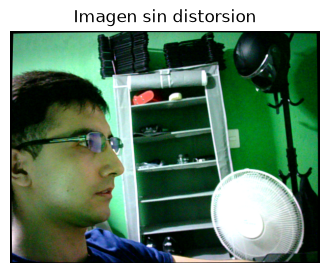

In [36]:
# Mostrar lo que captura la camara
distorted_image_bgr=camera.show_camera(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)
K=camera.calibration_parameters["camera"]["K"]
q=camera.calibration_parameters["camera"]["q"]
undistorted_image_rgb=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr, K, q)
plot_image(undistorted_image_rgb, title=f"Imagen sin distorsion", figsize=(4,4))

# Comprobar parametros de calibracion con realidad aumentada <a class='anchor' id='cpc'>

Una buena forma de comprobar que los parametros de la camara estan bien calculados es haciendo realidad aumentada, ya que implica utilizar el modelo de proyeccion de la camara para poder proyectar puntos 3D sobre el plano de imagen.

Se dibuja un rectangulo sobre el tablero de ajedrez que se uso para tomar las imagenes.

In [37]:
camera.camera_augmented_reality(fast=False, max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)